In [1]:
# This notebook will run the gene embedding once and save it. Then later any test data can load 1) saved gene embedding; 2) 89 gene list; 
# 3) the original adata 4) prediction csv file. 
# Slim, modulized

In [3]:
!which python3
# /mnt/pixstor/data/lsxgf/miniconda/envs/py-contrastLearn-py3.10-R4.1-cuda11.7-torch1.13/bin/python3

/mnt/pixstor/data/lsxgf/miniconda/envs/py-contrastLearn-py3.10-R4.1-cuda11.7-torch1.13/bin/python3


In [4]:
import scanpy as sc
import scvi
import numpy as np
import pandas as pd
from anndata import AnnData

import argparse
import copy
import gc
import json
import os
from pathlib import Path
import shutil
import sys
import time
import traceback
from typing import List, Tuple, Dict, Union, Optional
import warnings

import pickle
import seaborn as sns
import torch
#from torchsampler import ImbalancedDatasetSampler

#import cosine_annealing_warmup #you need to install this from github:https://github.com/katsura-jp/pytorch-cosine-annealing-with-warmup and study this.

#import wandb
from scipy.sparse import issparse
import matplotlib.pyplot as plt
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import balanced_accuracy_score, f1_score
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from torchtext.vocab import Vocab
from torchtext._torchtext import (
    Vocab as VocabPybind,
)

sys.path.insert(0, "/cluster/pixstor/xudong-lab/suli/tools_related/scGPT/")
from scgpt.tokenizer.gene_tokenizer import GeneVocab

import scgpt as scg
from scgpt.model import TransformerModel, AdversarialDiscriminator
from scgpt.tokenizer import tokenize_and_pad_batch, random_mask_value
from scgpt.loss import (
    masked_mse_loss,
    masked_relative_error,
    criterion_neg_log_bernoulli,
)
from scgpt.preprocess import Preprocessor
from scgpt import SubsetsBatchSampler
from scgpt.utils import set_seed, category_str2int, eval_scib_metrics

from itertools import cycle
from sklearn import svm, datasets
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import roc_auc_score

Global seed set to 0
<frozen importlib._bootstrap>:914: ImportWarning: _SixMetaPathImporter.find_spec() not found; falling back to find_module()


In [5]:
set_seed(0)
pad_token = "<pad>"
special_tokens = [pad_token, "<cls>", "<eoc>"]
n_hvg = 1200
n_bins = 51
mask_value = -1
pad_value = -2
n_input_bins = n_bins

In [8]:
pt_posttrain = False

In [9]:
# Specify model path; here we load the pre-trained scGPT blood model
if Path('/cluster/pixstor/xudong-lab/suli/').exists():
    local_path = '/cluster/pixstor/xudong-lab/suli/'
elif Path('/fs/ess/PCON0022/lsxgf/').exists():
    local_path = '/fs/ess/PCON0022/lsxgf/'
model_dir = Path(f"{local_path}tools_related/scgpt_data_model/scGPT_bc")
model_config_file = model_dir / "args.json"

vocab_file = model_dir / "vocab.json"

if pt_posttrain == True:
    model_file = Path(post_train_pt)
else:
    model_file = model_dir / "best_model.pt"

vocab = GeneVocab.from_file(vocab_file)
for s in special_tokens:
    if s not in vocab:
        vocab.append_token(s)

# Retrieve model parameters from config files
with open(model_config_file, "r") as f:
    model_configs = json.load(f)
print(
    f"Resume model from {model_file}, the model args will override the "
    f"config {model_config_file}."
)
embsize = model_configs["embsize"]
nhead = model_configs["nheads"]
d_hid = model_configs["d_hid"]
nlayers = model_configs["nlayers"]
n_layers_cls = model_configs["n_layers_cls"]

gene2idx = vocab.get_stoi()

Resume model from /cluster/pixstor/xudong-lab/suli/tools_related/scgpt_data_model/scGPT_bc/best_model.pt, the model args will override the config /cluster/pixstor/xudong-lab/suli/tools_related/scgpt_data_model/scGPT_bc/args.json.


In [10]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

ntokens = len(vocab)  # size of vocabulary
model = TransformerModel(
    ntokens,
    embsize,
    nhead,
    d_hid,
    nlayers,
    vocab=vocab,
    pad_value=pad_value,
    n_input_bins=n_input_bins,
)

try:
    model.load_state_dict(torch.load(model_file, map_location=torch.device(device)))
    print(f"Loading all model params from {model_file}")
except:
    # only load params that are in the model and match the size
    model_dict = model.state_dict()
    pretrained_dict = torch.load(model_file, map_location=torch.device(device))
    pretrained_dict = {
        k: v
        for k, v in pretrained_dict.items()
        if k in model_dict and v.shape == model_dict[k].shape
    }
    for k, v in pretrained_dict.items():
        print(f"Loading params {k} with shape {v.shape}")
        model_dict.update(pretrained_dict)
        model.load_state_dict(model_dict)

model.to(device)


Loading params encoder.embedding.weight with shape torch.Size([36574, 512])
Loading params encoder.enc_norm.weight with shape torch.Size([512])
Loading params encoder.enc_norm.bias with shape torch.Size([512])
Loading params value_encoder.linear1.weight with shape torch.Size([512, 1])
Loading params value_encoder.linear1.bias with shape torch.Size([512])
Loading params value_encoder.linear2.weight with shape torch.Size([512, 512])
Loading params value_encoder.linear2.bias with shape torch.Size([512])
Loading params value_encoder.norm.weight with shape torch.Size([512])
Loading params value_encoder.norm.bias with shape torch.Size([512])
Loading params transformer_encoder.layers.0.self_attn.out_proj.weight with shape torch.Size([512, 512])
Loading params transformer_encoder.layers.0.self_attn.out_proj.bias with shape torch.Size([512])
Loading params transformer_encoder.layers.0.linear1.weight with shape torch.Size([512, 512])
Loading params transformer_encoder.layers.0.linear1.bias with 

TransformerModel(
  (encoder): GeneEncoder(
    (embedding): Embedding(36574, 512, padding_idx=36571)
    (enc_norm): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
  )
  (value_encoder): ContinuousValueEncoder(
    (dropout): Dropout(p=0.5, inplace=False)
    (linear1): Linear(in_features=1, out_features=512, bias=True)
    (activation): ReLU()
    (linear2): Linear(in_features=512, out_features=512, bias=True)
    (norm): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
  )
  (transformer_encoder): TransformerEncoder(
    (layers): ModuleList(
      (0): TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=512, out_features=512, bias=True)
        )
        (linear1): Linear(in_features=512, out_features=512, bias=True)
        (dropout): Dropout(p=0.5, inplace=False)
        (linear2): Linear(in_features=512, out_features=512, bias=True)
        (norm1): LayerNorm((512,), eps=1e-05, elementwis

In [11]:
device

device(type='cpu')

In [14]:
# load the data:
train_data_path = Path('/cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/processed_data/classifier/six_studies/test_zheng/hvg2000_by_study_6_89_genes/train_5_S_6Inter89.h5ad')
adata = sc.read_h5ad(train_data_path)
adata.var["gene_name"] = adata.var.index.tolist()
data_is_raw = False

In [15]:
preprocessor = Preprocessor(
    use_key="X",  # the key in adata.layers to use as raw data
    filter_gene_by_counts=False,  # step 1
    filter_cell_by_counts=False,  # step 2
    normalize_total=False,  # 3. whether to normalize the raw data and to what sum
    result_normed_key="X",  # the key in adata.layers to store the normalized data
    log1p=data_is_raw,  # 4. whether to log1p the normalized data
    result_log1p_key="X",
    subset_hvg=False,  # 5. whether to subset the raw data to highly variable genes
    hvg_flavor="seurat_v3" if data_is_raw else "cell_ranger",
    binning=n_bins,  # 6. whether to bin the raw data and to what number of bins
    result_binned_key="X_binned",  # the key in adata.layers to store the binned data
)
preprocessor(adata, batch_key = None)

scGPT - INFO - Binning data ...


In [16]:
# Retrieve the data-independent gene embeddings from scGPT
gene_ids = np.array([id for id in gene2idx.values()])
gene_embeddings = model.encoder(torch.tensor(gene_ids, dtype=torch.long).to(device))
gene_embeddings = gene_embeddings.detach().cpu().numpy()

In [17]:
# Filter on the intersection between the Immune Human HVGs found in step 1.2 and scGPT's 30+K foundation model vocab
gene_embeddings = {gene: gene_embeddings[i] for i, gene in enumerate(gene2idx.keys()) if gene in adata.var.index.tolist()}
print('Retrieved gene embeddings for {} genes.'.format(len(gene_embeddings)))

Retrieved gene embeddings for 89 genes.


In [24]:
preprocessor = Preprocessor(
    use_key="X",  # the key in adata.layers to use as raw data
    filter_gene_by_counts=False,  # step 1
    filter_cell_by_counts=False,  # step 2
    normalize_total=False,  # 3. whether to normalize the raw data and to what sum
    result_normed_key="X",  # the key in adata.layers to store the normalized data
    log1p=data_is_raw,  # 4. whether to log1p the normalized data
    result_log1p_key="X",
    subset_hvg=False,  # 5. whether to subset the raw data to highly variable genes
    hvg_flavor="seurat_v3" if data_is_raw else "cell_ranger",
    binning=n_bins,  # 6. whether to bin the raw data and to what number of bins
    result_binned_key="X_binned",  # the key in adata.layers to store the binned data
)
preprocessor(adata, batch_key = None)

scGPT - INFO - Binning data ...


In [25]:
# Retrieve the data-independent gene embeddings from scGPT
gene_ids = np.array([id for id in gene2idx.values()])
gene_embeddings = model.encoder(torch.tensor(gene_ids, dtype=torch.long).to(device))
gene_embeddings = gene_embeddings.detach().cpu().numpy()

In [26]:
# Filter on the intersection between the Immune Human HVGs found in step 1.2 and scGPT's 30+K foundation model vocab
gene_embeddings = {gene: gene_embeddings[i] for i, gene in enumerate(gene2idx.keys()) if gene in adata.var.index.tolist()}
print('Retrieved gene embeddings for {} genes.'.format(len(gene_embeddings)))

Retrieved gene embeddings for 89 genes.


In [22]:
gene_embeddings['CXCL13'].dtype

dtype('float32')

In [23]:
gene_embeddings['CXCL13'].size

512

In [24]:
gene_embeddings['CXCL13']

array([-5.60679674e-01,  4.96751159e-01,  2.92384148e+00, -5.57997644e-01,
       -9.76088703e-01, -1.65873551e+00,  1.58542311e+00, -7.52603531e-01,
        4.20656949e-01, -2.93635011e-01,  1.37571442e+00, -1.21452935e-01,
       -1.58808351e+00, -1.41464019e+00,  8.82420838e-01,  2.09692979e+00,
       -2.10627437e+00, -1.14937209e-01,  2.02441558e-01, -1.93602219e-02,
       -8.77891555e-02, -1.38512313e+00, -3.35643291e-01, -6.20025516e-01,
       -1.25556648e+00,  9.15625036e-01,  1.89249411e-01, -9.25091505e-01,
       -1.27583492e+00,  1.30283630e+00, -5.96820638e-02,  1.24436831e+00,
        1.31982431e-01,  9.70600322e-02, -5.07375360e-01,  1.52025175e+00,
       -2.35628605e-01,  7.89160252e-01,  3.79195750e-01,  1.20536971e+00,
        1.77506769e+00,  5.25205851e-01, -2.70653105e+00,  2.83696532e+00,
       -4.60259557e-01,  1.12510037e+00,  5.17408609e-01, -1.00142670e+00,
       -3.77462879e-02, -4.38653827e-01, -1.34509206e+00, -8.87489617e-01,
       -9.82028127e-01,  

In [26]:
from pathlib import Path

out_dir_root = Path("/cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/results/classifier/model_explainability/Model_expl_20260814")
os.makedirs(out_dir_root, exist_ok=True)

# later the output_dir should be out_dir_root / f'prediction_cell-clone_predict'
np.savez_compressed(out_dir_root / "gene_embeddings_forReuse.npz", **gene_embeddings)

## Start from here
### re-load:

In [1]:
import scanpy as sc
import numpy as np
import pandas as pd
from anndata import AnnData

import argparse
import copy
import gc
import json
import os
from pathlib import Path
import shutil
import sys
import time
import traceback
from typing import List, Tuple, Dict, Union, Optional
import warnings

import pickle
import seaborn as sns



sys.path.insert(0, "/cluster/pixstor/xudong-lab/suli/tools_related/scGPT/")
from scgpt.tasks import GeneEmbedding


<frozen importlib._bootstrap>:914: ImportWarning: _SixMetaPathImporter.find_spec() not found; falling back to find_module()
<frozen importlib._bootstrap>:914: ImportWarning: _SixMetaPathImporter.find_spec() not found; falling back to find_module()
<frozen importlib._bootstrap>:914: ImportWarning: _SixMetaPathImporter.find_spec() not found; falling back to find_module()
<frozen importlib._bootstrap>:914: ImportWarning: _SixMetaPathImporter.find_spec() not found; falling back to find_module()
<frozen importlib._bootstrap>:914: ImportWarning: _SixMetaPathImporter.find_spec() not found; falling back to find_module()
<frozen importlib._bootstrap>:914: ImportWarning: _SixMetaPathImporter.find_spec() not found; falling back to find_module()


In [2]:
from pathlib import Path

out_dir_root = Path("/cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/results/classifier/model_explainability/Model_expl_20260814")
os.makedirs(out_dir_root, exist_ok=True)

loaded = np.load(out_dir_root / "gene_embeddings_forReuse.npz")
gene_embeddings = {gene: loaded[gene] for gene in loaded.files}

In [3]:
sctrp_panel_list = list(gene_embeddings.keys())

In [4]:
# Construct gene embedding network
embed = GeneEmbedding(gene_embeddings)

100%|████████████████████████████████████████████████████████████████████████████████████████████| 89/89 [00:00<00:00, 794240.54it/s]


In [5]:
test_data_path = Path("/cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/data_collection/chiffelle_melanoma_Immunity/rawCount_adatas_cd8/chiffelle_15samples_CD8_log1p.h5ad")

In [6]:

test_adata = sc.read_h5ad(test_data_path)
data_is_raw = False

test_adata.var["gene_name"] = test_adata.var.index.tolist()



In [7]:
# make sure the train and test data has same gene panel and all use the gene panel in the training dataset:
import anndata as ad

# Create an empty (0-cell) scaffold AnnData with the target gene list,
# just to drive the outer-join gene alignment — no need to load real adata
dummy = ad.AnnData(
    np.zeros((0, len(sctrp_panel_list)), dtype=test_adata.X.dtype),
    var=pd.DataFrame(index=sctrp_panel_list)
)

test_adata = ad.concat([dummy, test_adata], join="outer", fill_value=0)[
    list(test_adata.obs_names), sctrp_panel_list
]

test_adata.var["gene_name"] = test_adata.var.index.tolist()

/tmp/ipykernel_4097190/1993678651.py:15: ImplicitModificationWarning: Trying to modify attribute `.var` of view, initializing view as actual.
  test_adata.var["gene_name"] = test_adata.var.index.tolist()


In [8]:
test_adata

AnnData object with n_obs × n_vars = 16727 × 89
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rt', 'pct_counts_rt', 'n_genes', 'VJ_1_v_call', 'VJ_1_cdr3_aa', 'VJ_1_j_call', 'VDJ_1_v_call', 'VDJ_1_cdr3_aa', 'VDJ_1_j_call', 'VJ_2_v_call', 'VJ_2_cdr3_aa', 'VJ_2_j_call', 'VDJ_2_v_call', 'VDJ_2_cdr3_aa', 'VDJ_2_j_call', 'cdr3_aa', 'sample', 'sample_clone_id', 'cc_aa_identity', 'Tumor-reactivity', 'Clonally_expanded_in_T0', 'Clonally_expanded_in_ACTP', 'Extracted_from_the_CD137plus_fraction', 'Described_in_Arnaud_etal', 'Coming_from_other_sources', 'Original_clonotype_id', 'reactivity', 'reactivity_fine', 'ori_CD48', 'cell_type_singler', 'CD_0220_agree', 'sample_clone_id_ORI'
    var: 'gene_name'

In [9]:
test_adata.obs[test_adata.obs['sample_clone_id_ORI'] =='chiffelle_Patient8_T0_45'][['sample_clone_id', 'cc_aa_identity', 'sample_clone_id_ORI']].head()

,sample_clone_id,cc_aa_identity,sample_clone_id_ORI
AACCGCGGTAGATTAG-patient8_T0_CD45,chiffelle_Patient8_T0_46,chiffelle_Patient8_T0_46,chiffelle_Patient8_T0_45
AACTCAGGTCAATACC-patient8_T0_CD45,chiffelle_Patient8_T0_46,chiffelle_Patient8_T0_46,chiffelle_Patient8_T0_45
AACTTTCGTCAGAGGT-patient8_T0_CD45,chiffelle_Patient8_T0_69,chiffelle_Patient8_T0_69,chiffelle_Patient8_T0_45
AAGGTTCAGTGACTCT-patient8_T0_CD45,chiffelle_Patient8_T0_85,chiffelle_Patient8_T0_85,chiffelle_Patient8_T0_45
ACACCCTAGCAACGGT-patient8_T0_CD45,chiffelle_Patient8_T0_65,chiffelle_Patient8_T0_65,chiffelle_Patient8_T0_45


In [10]:
ensemble_mode = 'rankMin_study'
level = 'clonotype'

if level == 'cell':
    sub_d = 'raw_cell_scores'
elif level == 'clonotype':
    sub_d = 'pooled_scores/max'

output_dir = out_dir_root / f'{ensemble_mode}_{level}' 
os.makedirs(output_dir, exist_ok=True)

sctrp_label_fi = Path(f"/cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/results/classifier/case_study/ICB_chiffelle_5case_inference_6AllasTrain/unified_cell_predictions/{sub_d}/scTRP_simclr_{ensemble_mode}_chiffelle.csv")
print(sctrp_label_fi)

/cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/results/classifier/case_study/ICB_chiffelle_5case_inference_6AllasTrain/unified_cell_predictions/pooled_scores/max/scTRP_simclr_rankMin_study_chiffelle.csv


In [11]:
sctrp_label_df = pd.read_csv(sctrp_label_fi)

<frozen importlib._bootstrap>:914: ImportWarning: _SixMetaPathImporter.find_spec() not found; falling back to find_module()


In [12]:
sctrp_label_df.head()

,cell_barcode,score,reactivity,sample_clone_id,sample,reactivity_fine
0,AAACGGGGTCAGAGGT-patient12_T0_CD45,1817.0,0,chiffelle_Patient12_T0_7,chiffelle_Patient12_T0,8
1,AACACGTGTACCGAGA-patient12_T0_CD45,1673.0,0,chiffelle_Patient12_T0_27,chiffelle_Patient12_T0,8
2,AACGTTGCACGGCTAC-patient12_T0_CD45,2978.5,0,chiffelle_Patient12_T0_34,chiffelle_Patient12_T0,8
3,AACGTTGGTTGAACTC-patient12_T0_CD45,5457.0,0,chiffelle_Patient12_T0_37,chiffelle_Patient12_T0,8
4,AACGTTGGTTGCGTTA-patient12_T0_CD45,69.0,0,chiffelle_Patient12_T0_38,chiffelle_Patient12_T0,8


In [13]:
sctrp_label_df.shape

(16727, 6)

In [14]:
import numpy as np
import pandas as pd
import jenkspy


def add_jenks_pred(df: pd.DataFrame) -> pd.DataFrame:
    """Apply per-sample Jenks natural-breaks prediction on 'score'.

    Groups by 'sample', finds the 2-class Jenks threshold within each group,
    and sets pred=1 for cells above the threshold, pred=0 otherwise.

    Edge cases:
      - Fewer than 2 cells in a sample → pred=0 for all
      - All scores identical (no natural break) → pred=0 for all
      - jenkspy raises any exception → pred=0 for all, warning printed
    """
    df = df.copy()
    df['pred'] = 0  # default

    for samp, grp in df.groupby('sample'):
        scores = grp['score'].dropna().values.astype(float)

        if len(scores) < 2 or np.unique(scores).size < 2:
            continue  # leave pred=0

        try:
            breaks = jenkspy.jenks_breaks(scores.tolist(), n_classes=2)
            thresh = breaks[1]
            df.loc[grp.index, 'pred'] = (scores > thresh).astype(int)
        except Exception as e:
            print(f"  [jenks] skip sample '{samp}': {e}")

    return df




In [15]:
'pred' not in sctrp_label_df.columns

True

In [16]:
if 'pred' not in sctrp_label_df.columns:
    sctrp_label_df = add_jenks_pred(sctrp_label_df)

In [17]:
pred_map = sctrp_label_df.set_index('cell_barcode')['pred']
test_adata.obs['scTRP_pred'] = test_adata.obs_names.map(pred_map)

In [18]:
test_adata.obs['scTRP_pred'].value_counts()

0    9060
1    7667
Name: scTRP_pred, dtype: int64

In [19]:
# test_adata.obs['scTRP_pred'].value_counts()
# rank_majority: 0    12827 1     3900

sctrp_label_fi2 = Path("/cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/results/classifier/case_study/ICB_chiffelle_5case_inference_6AllasTrain/unified_cell_predictions/pooled_scores/max/scTRP_simclr_rank_majority_chiffelle.csv")
sctrp_label_df2 = pd.read_csv(sctrp_label_fi2)
sctrp_label_df2.head()

sctrp_label_df2.shape

pred_map = sctrp_label_df2.set_index('cell_barcode')['pred']
test_adata.obs['scTRP_clonotypeLevel_pred'] = test_adata.obs_names.map(pred_map)
print(test_adata.obs['scTRP_clonotypeLevel_pred'].value_counts())

In [20]:
test_adata

AnnData object with n_obs × n_vars = 16727 × 89
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rt', 'pct_counts_rt', 'n_genes', 'VJ_1_v_call', 'VJ_1_cdr3_aa', 'VJ_1_j_call', 'VDJ_1_v_call', 'VDJ_1_cdr3_aa', 'VDJ_1_j_call', 'VJ_2_v_call', 'VJ_2_cdr3_aa', 'VJ_2_j_call', 'VDJ_2_v_call', 'VDJ_2_cdr3_aa', 'VDJ_2_j_call', 'cdr3_aa', 'sample', 'sample_clone_id', 'cc_aa_identity', 'Tumor-reactivity', 'Clonally_expanded_in_T0', 'Clonally_expanded_in_ACTP', 'Extracted_from_the_CD137plus_fraction', 'Described_in_Arnaud_etal', 'Coming_from_other_sources', 'Original_clonotype_id', 'reactivity', 'reactivity_fine', 'ori_CD48', 'cell_type_singler', 'CD_0220_agree', 'sample_clone_id_ORI', 'scTRP_pred'
    var: 'gene_name'

In [21]:
# Perform Louvain clustering with desired resolution; here we specify resolution=40
gdata = embed.get_adata(resolution=3)
# Retrieve the gene clusters
metagenes = embed.get_metagenes(gdata)

<frozen importlib._bootstrap>:914: ImportWarning: _SixMetaPathImporter.find_spec() not found; falling back to find_module()


In [22]:
metagenes

defaultdict(list,
            {'9': ['XCL2', 'TRAV16', 'LAIR2', 'DTHD1', 'IFNG'],
             '14': ['XCL1', 'AREG'],
             '1': ['TRGV5',
              'TRDV1',
              'GNLY',
              'FGFBP2',
              'KLRD1',
              'ZNF683',
              'GZMB',
              'GZMH',
              'GZMA'],
             '4': ['TRBV6-5',
              'TRBV5-6',
              'TRAV12-3',
              'TRBV18',
              'CXCL13',
              'GZMK',
              'IL7R'],
             '8': ['TRAV4', 'RGS2', 'BCL2A1', 'C1orf162', 'FGL2', 'KLF10'],
             '0': ['TIMP1',
              'ANXA1',
              'FRMD4B',
              'CCL20',
              'HMOX1',
              'MT1E',
              'LGALS1',
              'LMNA',
              'SAT1'],
             '5': ['STMN1',
              'TUBB',
              'HSPB1',
              'DNAJB1',
              'TUBA1B',
              'HSPA1A',
              'HSPA1B'],
             '7': ['TNF',
            

In [23]:
# Obtain the set of gene programs from clusters with #genes >= 5
mgs = dict()
for mg, genes in metagenes.items():
    if len(genes) > 1:
        mgs[mg] = genes

In [24]:
mgs

{'9': ['XCL2', 'TRAV16', 'LAIR2', 'DTHD1', 'IFNG'],
 '14': ['XCL1', 'AREG'],
 '1': ['TRGV5',
  'TRDV1',
  'GNLY',
  'FGFBP2',
  'KLRD1',
  'ZNF683',
  'GZMB',
  'GZMH',
  'GZMA'],
 '4': ['TRBV6-5', 'TRBV5-6', 'TRAV12-3', 'TRBV18', 'CXCL13', 'GZMK', 'IL7R'],
 '8': ['TRAV4', 'RGS2', 'BCL2A1', 'C1orf162', 'FGL2', 'KLF10'],
 '0': ['TIMP1',
  'ANXA1',
  'FRMD4B',
  'CCL20',
  'HMOX1',
  'MT1E',
  'LGALS1',
  'LMNA',
  'SAT1'],
 '5': ['STMN1', 'TUBB', 'HSPB1', 'DNAJB1', 'TUBA1B', 'HSPA1A', 'HSPA1B'],
 '7': ['TNF', 'RGS1', 'GADD45B', 'CCL3', 'DUSP2', 'CCL4L2', 'CCL4'],
 '3': ['TNFRSF18', 'FASLG', 'TRDC', 'TIGIT', 'KLRC1', 'CADM1', 'LAYN'],
 '2': ['FOS', 'FTL', 'DUSP1', 'DDIT3', 'GADD45G', 'CD69', 'RGS16'],
 '12': ['CRTAM', 'DKK3', 'KLRG1'],
 '13': ['PDE7B', 'SELL'],
 '15': ['CXCR6', 'PMCH'],
 '11': ['ALOX5AP', 'AUTS2', 'KLRB1', 'HOPX'],
 '6': ['MYC', 'LEF1', 'CD40LG', 'CCR7', 'MAL', 'SESN3', 'IL2RA'],
 '10': ['IRF4', 'HLA-DRA', 'CD83', 'GPR183', 'MTSS1']}

<frozen importlib._bootstrap>:914: ImportWarning: _SixMetaPathImporter.find_spec() not found; falling back to find_module()
/mnt/pixstor/data/lsxgf/miniconda/envs/py-contrastLearn-py3.10-R4.1-cuda11.7-torch1.13/lib/python3.10/site-packages/seaborn/matrix.py:589: DeprecationWarning: `product` is deprecated as of NumPy 1.25.0, and will be removed in NumPy 2.0. Please use `prod` instead.
  self.linkage = self.calculated_linkage
<frozen importlib._bootstrap>:914: ImportWarning: _SixMetaPathImporter.find_spec() not found; falling back to find_module()
/mnt/pixstor/data/lsxgf/miniconda/envs/py-contrastLearn-py3.10-R4.1-cuda11.7-torch1.13/lib/python3.10/site-packages/seaborn/matrix.py:589: DeprecationWarning: `product` is deprecated as of NumPy 1.25.0, and will be removed in NumPy 2.0. Please use `prod` instead.
  self.linkage = self.calculated_linkage
/mnt/pixstor/data/lsxgf/miniconda/envs/py-contrastLearn-py3.10-R4.1-cuda11.7-torch1.13/lib/python3.10/site-packages/seaborn/matrix.py:213: Mat

<Figure size 360x936 with 0 Axes>

<Figure size 432x288 with 0 Axes>

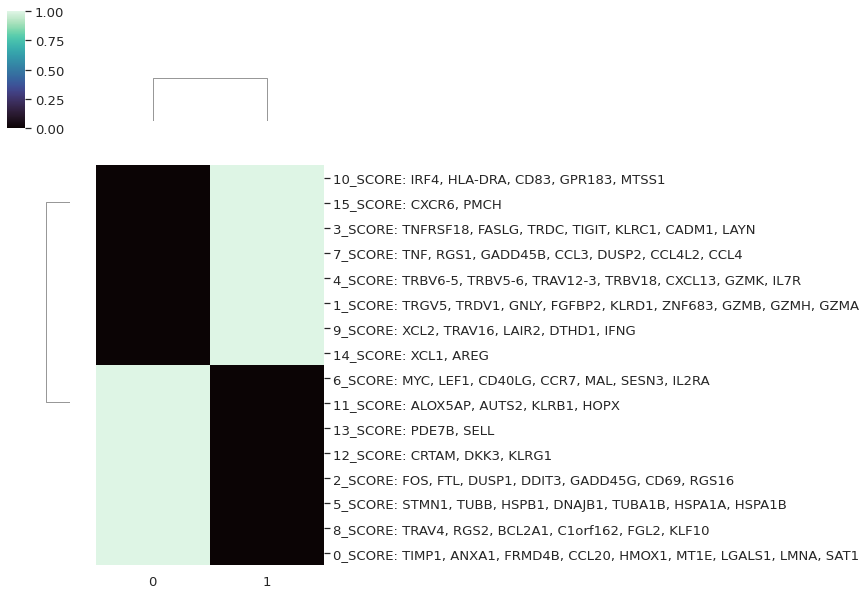

In [25]:
sns.set(font_scale=1.2)
embed.score_metagenes(test_adata, metagenes)
embed.plot_metagenes_scores(test_adata, mgs, "scTRP_pred")  #"reactivity_fine")

In [26]:
test_adata

AnnData object with n_obs × n_vars = 16727 × 89
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rt', 'pct_counts_rt', 'n_genes', 'VJ_1_v_call', 'VJ_1_cdr3_aa', 'VJ_1_j_call', 'VDJ_1_v_call', 'VDJ_1_cdr3_aa', 'VDJ_1_j_call', 'VJ_2_v_call', 'VJ_2_cdr3_aa', 'VJ_2_j_call', 'VDJ_2_v_call', 'VDJ_2_cdr3_aa', 'VDJ_2_j_call', 'cdr3_aa', 'sample', 'sample_clone_id', 'cc_aa_identity', 'Tumor-reactivity', 'Clonally_expanded_in_T0', 'Clonally_expanded_in_ACTP', 'Extracted_from_the_CD137plus_fraction', 'Described_in_Arnaud_etal', 'Coming_from_other_sources', 'Original_clonotype_id', 'reactivity', 'reactivity_fine', 'ori_CD48', 'cell_type_singler', 'CD_0220_agree', 'sample_clone_id_ORI', 'scTRP_pred', '9_SCORE', '14_SCORE', '1_SCORE', '4_SCORE', '8_SCORE', '0_SCORE', '5_SCORE', '7_SCORE', '3_SCORE', '2_SCORE', '12_SCORE', '13_SCORE', '15_SCORE', '11_SCORE', '6_SCORE', '10_SCORE'
    var: 'gene_name'

In [27]:
import numpy as np
import pandas as pd
from itertools import combinations
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

def differential_metagenes_pairwise(
    df: pd.DataFrame,
    group_col: str = "reactivity_fine",
    groups=("0", "1", "8"),
    score_cols=None,
    use_median: bool = True,
):
    """
    Pairwise differential analysis for metagene score columns between groups.

    Returns a dict keyed by comparisons like "0_vs_1", each value a DataFrame with:
    metagene, effect (groupA - groupB), centers, pvalue, fdr, nA, nB.
    """
    if score_cols is None:
        score_cols = [c for c in df.columns if c.endswith("_SCORE")]

    # Ensure consistent string comparison
    gseries = df[group_col].astype(str)

    out = {}
    for a, b in combinations([str(g) for g in groups], 2):
        A = df.loc[gseries == a, score_cols]
        B = df.loc[gseries == b, score_cols]

        rows = []
        for col in score_cols:
            x = A[col].dropna().values
            y = B[col].dropna().values
            if len(x) < 3 or len(y) < 3:
                continue

            if use_median:
                center_x = float(np.median(x))
                center_y = float(np.median(y))
            else:
                center_x = float(np.mean(x))
                center_y = float(np.mean(y))

            effect = center_x - center_y

            test = mannwhitneyu(x, y, alternative="two-sided")
            rows.append({
                "comparison": f"{a}_vs_{b}",
                "metagene": col,
                "effect": effect,  # positive => higher in group a
                "center_groupA": center_x,
                "center_groupB": center_y,
                "pvalue": float(test.pvalue),
                "n_groupA": int(len(x)),
                "n_groupB": int(len(y)),
            })

        res = pd.DataFrame(rows)
        if len(res) == 0:
            out[f"{a}_vs_{b}"] = res
            continue

        # BH FDR correction within this comparison
        res["fdr"] = multipletests(res["pvalue"].values, method="fdr_bh")[1]

        # Rank: most significant then biggest absolute effect
        res = res.sort_values(["fdr", "pvalue", "effect"], ascending=[True, True, False]).reset_index(drop=True)
        out[f"{a}_vs_{b}"] = res

    return out


In [28]:
score_cols = [x for x in test_adata.obs.columns if x.endswith("_SCORE")]

pairwise_res = differential_metagenes_pairwise(
    df=test_adata.obs,
    group_col="scTRP_pred",
    groups=("0", "1"),
    score_cols=score_cols,
    use_median=True
)

pairwise_res["0_vs_1"].head(10)


,comparison,metagene,effect,center_groupA,center_groupB,pvalue,n_groupA,n_groupB,fdr
0,0_vs_1,3_SCORE,-0.061242,0.443765,0.505007,0.000000e+00,9060,7667,0.000000e+00
1,0_vs_1,5_SCORE,0.054550,0.360483,0.305933,1.026104e-208,9060,7667,8.208834e-208
2,0_vs_1,1_SCORE,-0.063866,0.428045,0.491911,7.400944e-170,9060,7667,3.947170e-169
3,0_vs_1,12_SCORE,0.040817,0.465906,0.425088,2.179440e-141,9060,7667,8.717762e-141
4,0_vs_1,0_SCORE,0.035296,0.392693,0.357397,7.987793e-122,9060,7667,2.556094e-121
5,0_vs_1,6_SCORE,0.028233,0.348547,0.320315,3.410214e-121,9060,7667,9.093903e-121
6,0_vs_1,14_SCORE,0.000000,0.392850,0.392850,1.325958e-113,9060,7667,3.030761e-113
7,0_vs_1,7_SCORE,-0.043779,0.426103,0.469882,1.416554e-104,9060,7667,2.833107e-104
8,0_vs_1,2_SCORE,0.057307,0.525149,0.467842,6.530716e-99,9060,7667,1.161016e-98
9,0_vs_1,8_SCORE,0.013269,0.427181,0.413912,6.435868e-32,9060,7667,1.029739e-31


In [29]:
pairwise_res['0_vs_1']

,comparison,metagene,effect,center_groupA,center_groupB,pvalue,n_groupA,n_groupB,fdr
0,0_vs_1,3_SCORE,-0.061242,0.443765,0.505007,0.000000e+00,9060,7667,0.000000e+00
1,0_vs_1,5_SCORE,0.054550,0.360483,0.305933,1.026104e-208,9060,7667,8.208834e-208
2,0_vs_1,1_SCORE,-0.063866,0.428045,0.491911,7.400944e-170,9060,7667,3.947170e-169
3,0_vs_1,12_SCORE,0.040817,0.465906,0.425088,2.179440e-141,9060,7667,8.717762e-141
4,0_vs_1,0_SCORE,0.035296,0.392693,0.357397,7.987793e-122,9060,7667,2.556094e-121
5,0_vs_1,6_SCORE,0.028233,0.348547,0.320315,3.410214e-121,9060,7667,9.093903e-121
6,0_vs_1,14_SCORE,0.000000,0.392850,0.392850,1.325958e-113,9060,7667,3.030761e-113
7,0_vs_1,7_SCORE,-0.043779,0.426103,0.469882,1.416554e-104,9060,7667,2.833107e-104
8,0_vs_1,2_SCORE,0.057307,0.525149,0.467842,6.530716e-99,9060,7667,1.161016e-98
9,0_vs_1,8_SCORE,0.013269,0.427181,0.413912,6.435868e-32,9060,7667,1.029739e-31


In [30]:
import pandas as pd
from collections import defaultdict

# 1) Get significant metagenes for 0_vs_1
res01 = pairwise_res["0_vs_1"].copy()

sig = res01[res01["fdr"] < 0.05].copy()

# Parse metagene id so it matches keys in mgs
# Handles "6_SCORE" -> "6" and also works if it is already "6"
sig["metagene_id"] = (
    sig["metagene"].astype(str)
    .str.replace("_SCORE", "", regex=False)
)

# 2) Sort by effect high to low
sig = sig.sort_values("effect", ascending=False).reset_index(drop=True)

# 3) Top 5 and bottom 5 metagenes
meta_list_0 = sig["metagene_id"].head(5).tolist()
meta_list_1 = sig["metagene_id"].tail(5).tolist()

# 4) Build gene level annotation dataframe
gene_to_metas = defaultdict(set)
gene_to_labels = defaultdict(set)

# Highest effect metagenes -> label 1
for mid in meta_list_1:
    for g in mgs.get(str(mid), []):
        gene_to_metas[g].add(str(mid))
        gene_to_labels[g].add("1")

# Lowest effect metagenes -> label 0
for mid in meta_list_0:
    for g in mgs.get(str(mid), []):
        gene_to_metas[g].add(str(mid))
        gene_to_labels[g].add("0")

rows = []
for gene in sorted(gene_to_metas.keys()):
    labels = gene_to_labels[gene]

    # If a gene appears in both lists, we keep label "1" by default and mark conflict
    conflict = len(labels) > 1
    label = "1" if "1" in labels else "0"

    metas = sorted(gene_to_metas[gene], key=lambda x: int(x) if x.isdigit() else x)
    rows.append(
        {
            "gene": gene,
            "celltype_label": label,          # "1" or "0"
            "metagenes": ",".join(metas),     # which metagene ids this gene came from
            "conflict": conflict,             # True if gene appears in both top and bottom lists
        }
    )

gene_annotation_df = pd.DataFrame(rows)




In [31]:
sig

,comparison,metagene,effect,center_groupA,center_groupB,pvalue,n_groupA,n_groupB,fdr,metagene_id
0,0_vs_1,2_SCORE,0.057307,0.525149,0.467842,6.530716e-99,9060,7667,1.161016e-98,2
1,0_vs_1,5_SCORE,0.054550,0.360483,0.305933,1.026104e-208,9060,7667,8.208834e-208,5
2,0_vs_1,12_SCORE,0.040817,0.465906,0.425088,2.179440e-141,9060,7667,8.717762e-141,12
3,0_vs_1,0_SCORE,0.035296,0.392693,0.357397,7.987793e-122,9060,7667,2.556094e-121,0
4,0_vs_1,6_SCORE,0.028233,0.348547,0.320315,3.410214e-121,9060,7667,9.093903e-121,6
5,0_vs_1,8_SCORE,0.013269,0.427181,0.413912,6.435868e-32,9060,7667,1.029739e-31,8
6,0_vs_1,11_SCORE,0.009595,0.394326,0.384731,5.962165e-06,9060,7667,6.813903e-06,11
7,0_vs_1,14_SCORE,0.000000,0.392850,0.392850,1.325958e-113,9060,7667,3.030761e-113,14
8,0_vs_1,15_SCORE,0.000000,0.443037,0.443037,2.186513e-07,9060,7667,2.915351e-07,15
9,0_vs_1,13_SCORE,0.000000,0.426377,0.426377,9.785179e-07,9060,7667,1.204330e-06,13


In [32]:
gene_annotation_df

,gene,celltype_label,metagenes,conflict
0,ANXA1,0,0,False
1,CADM1,1,3,False
2,CCL20,0,0,False
3,CCL3,1,7,False
4,CCL4,1,7,False
...,...,...,...,...
61,TRGV5,1,1,False
62,TUBA1B,0,5,False
63,TUBB,0,5,False
64,XCL2,1,9,False


In [33]:
gene_annotation_df.conflict.value_counts()

False    66
Name: conflict, dtype: int64

In [34]:
# Optional: keep only non conflict genes
gene_annotation_df_no_conflict = gene_annotation_df[~gene_annotation_df["conflict"]].reset_index(drop=True)

# gene_annotation_df is what you asked for

In [35]:
gene_annotation_df_no_conflict.shape

(66, 4)

In [36]:
mgs['9']

['XCL2', 'TRAV16', 'LAIR2', 'DTHD1', 'IFNG']

In [37]:
meta_list_1

['9', '10', '7', '3', '1']

In [38]:
gdata


AnnData object with n_obs × n_vars = 89 × 512
    obs: 'leiden'
    uns: 'neighbors', 'leiden', 'umap'
    obsm: 'X_umap'
    obsp: 'distances', 'connectivities'

In [39]:
gdata.obs

,leiden
XCL2,9
XCL1,14
TRGV5,1
TRDV1,1
TRBV6-5,4
...,...
GZMA,1
IL2RA,6
HSPA1B,5
PMCH,15


/mnt/pixstor/data/lsxgf/miniconda/envs/py-contrastLearn-py3.10-R4.1-cuda11.7-torch1.13/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  cax = scatter(


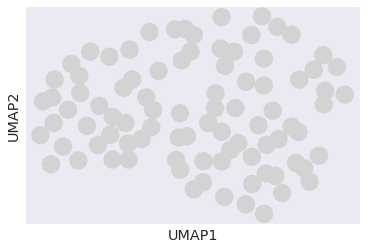

In [40]:
sc.pl.umap(gdata)

In [41]:
embed.embeddings.keys()

dict_keys(['XCL2', 'XCL1', 'TRGV5', 'TRDV1', 'TRBV6-5', 'TRBV5-6', 'TRAV4', 'TRAV16', 'TRAV12-3', 'TIMP1', 'STMN1', 'TUBB', 'TNF', 'RGS2', 'RGS1', 'GNLY', 'TNFRSF18', 'GADD45B', 'FOS', 'CCL3', 'DUSP2', 'HSPB1', 'FASLG', 'FTL', 'DNAJB1', 'DUSP1', 'TUBA1B', 'TRDC', 'FGFBP2', 'LAIR2', 'DTHD1', 'CRTAM', 'PDE7B', 'DDIT3', 'ANXA1', 'GADD45G', 'CXCR6', 'AREG', 'KLRD1', 'BCL2A1', 'ALOX5AP', 'AUTS2', 'C1orf162', 'MYC', 'LEF1', 'SELL', 'TIGIT', 'KLRC1', 'IRF4', 'FGL2', 'TRBV18', 'CCL4L2', 'FRMD4B', 'CD40LG', 'DKK3', 'HLA-DRA', 'CXCL13', 'CCL20', 'CADM1', 'CD69', 'CCR7', 'CD83', 'ZNF683', 'KLF10', 'GPR183', 'GZMB', 'GZMK', 'HMOX1', 'MT1E', 'HSPA1A', 'IFNG', 'LAYN', 'IL7R', 'GZMH', 'KLRB1', 'KLRG1', 'LGALS1', 'CCL4', 'LMNA', 'SAT1', 'MAL', 'RGS16', 'MTSS1', 'SESN3', 'GZMA', 'IL2RA', 'HSPA1B', 'PMCH', 'HOPX'])

In [42]:
test_adata

AnnData object with n_obs × n_vars = 16727 × 89
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rt', 'pct_counts_rt', 'n_genes', 'VJ_1_v_call', 'VJ_1_cdr3_aa', 'VJ_1_j_call', 'VDJ_1_v_call', 'VDJ_1_cdr3_aa', 'VDJ_1_j_call', 'VJ_2_v_call', 'VJ_2_cdr3_aa', 'VJ_2_j_call', 'VDJ_2_v_call', 'VDJ_2_cdr3_aa', 'VDJ_2_j_call', 'cdr3_aa', 'sample', 'sample_clone_id', 'cc_aa_identity', 'Tumor-reactivity', 'Clonally_expanded_in_T0', 'Clonally_expanded_in_ACTP', 'Extracted_from_the_CD137plus_fraction', 'Described_in_Arnaud_etal', 'Coming_from_other_sources', 'Original_clonotype_id', 'reactivity', 'reactivity_fine', 'ori_CD48', 'cell_type_singler', 'CD_0220_agree', 'sample_clone_id_ORI', 'scTRP_pred', '9_SCORE', '14_SCORE', '1_SCORE', '4_SCORE', '8_SCORE', '0_SCORE', '5_SCORE', '7_SCORE', '3_SCORE', '2_SCORE', '12_SCORE', '13_SCORE', '15_SCORE', '11_SCORE', '6_SCORE', '10_SCORE'
    var: 'gene_name'

In [43]:
gdata_path = output_dir / "Chiffelle_GRN_geneEmb.h5ad"
gdata.write(gdata_path)

### Save for re-use:

In [44]:
import pandas as pd 
import scanpy as sc
import matplotlib.pyplot as plt

from pathlib import Path


In [45]:
gdata_path = output_dir / "Chiffelle_GRN_geneEmb.h5ad"

gdata = sc.read_h5ad(gdata_path)

In [46]:
gdata

AnnData object with n_obs × n_vars = 89 × 512
    obs: 'leiden'
    uns: 'leiden', 'neighbors', 'umap'
    obsm: 'X_umap'
    obsp: 'connectivities', 'distances'

In [47]:
list(gdata.obs_names)[:4]

['XCL2', 'XCL1', 'TRGV5', 'TRDV1']

In [48]:
import tqdm
# Retrieve gene program 3 which contains the CD3 gene set
CD_genes = list(gdata.obs_names)
print(CD_genes)
# Compute cosine similarities among genes in this gene program
df_CD = pd.DataFrame(columns=['Gene', 'Similarity', 'Gene1'])
for i in tqdm.tqdm(CD_genes):
    df = embed.compute_similarities(i, CD_genes)
    df['Gene1'] = i
    df_CD = df_CD.append(df)
df_CD_sub = df_CD[df_CD['Similarity']<0.99].sort_values(by='Gene') # Filter out edges from each gene to itself

['XCL2', 'XCL1', 'TRGV5', 'TRDV1', 'TRBV6-5', 'TRBV5-6', 'TRAV4', 'TRAV16', 'TRAV12-3', 'TIMP1', 'STMN1', 'TUBB', 'TNF', 'RGS2', 'RGS1', 'GNLY', 'TNFRSF18', 'GADD45B', 'FOS', 'CCL3', 'DUSP2', 'HSPB1', 'FASLG', 'FTL', 'DNAJB1', 'DUSP1', 'TUBA1B', 'TRDC', 'FGFBP2', 'LAIR2', 'DTHD1', 'CRTAM', 'PDE7B', 'DDIT3', 'ANXA1', 'GADD45G', 'CXCR6', 'AREG', 'KLRD1', 'BCL2A1', 'ALOX5AP', 'AUTS2', 'C1orf162', 'MYC', 'LEF1', 'SELL', 'TIGIT', 'KLRC1', 'IRF4', 'FGL2', 'TRBV18', 'CCL4L2', 'FRMD4B', 'CD40LG', 'DKK3', 'HLA-DRA', 'CXCL13', 'CCL20', 'CADM1', 'CD69', 'CCR7', 'CD83', 'ZNF683', 'KLF10', 'GPR183', 'GZMB', 'GZMK', 'HMOX1', 'MT1E', 'HSPA1A', 'IFNG', 'LAYN', 'IL7R', 'GZMH', 'KLRB1', 'KLRG1', 'LGALS1', 'CCL4', 'LMNA', 'SAT1', 'MAL', 'RGS16', 'MTSS1', 'SESN3', 'GZMA', 'IL2RA', 'HSPA1B', 'PMCH', 'HOPX']


  0%|                                                                                                         | 0/89 [00:00<?, ?it/s]/cluster/pixstor/xudong-lab/suli/tools_related/scGPT/scgpt/tasks/grn.py:167: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  distance = float(
/cluster/pixstor/xudong-lab/suli/tools_related/scGPT/scgpt/tasks/grn.py:167: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  distance = float(
/cluster/pixstor/xudong-lab/suli/tools_related/scGPT/scgpt/tasks/grn.py:167: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from you

In [49]:
df_CD_sub = df_CD[(df_CD['Similarity']<0.99)&(df_CD['Similarity']>0.2)].sort_values(by='Gene') # Filter out edges from each gene to itself

In [50]:
df_CD_sub[df_CD_sub['Gene']=='CXCL13']

,Gene,Similarity,Gene1
4,CXCL13,0.223241,IL7R
6,CXCL13,0.209137,TRBV5-6
8,CXCL13,0.236731,GZMK


In [51]:
gdata

AnnData object with n_obs × n_vars = 89 × 512
    obs: 'leiden'
    uns: 'leiden', 'neighbors', 'umap'
    obsm: 'X_umap'
    obsp: 'connectivities', 'distances'

In [52]:
df_CD_sub.Similarity.min()


0.2000512033700943

In [53]:
df_CD_sub[df_CD_sub['Gene']=='CD83']

,Gene,Similarity,Gene1
1,CD83,0.320336,HLA-DRA
4,CD83,0.247886,CCL3
9,CD83,0.229113,CCL4L2
1,CD83,0.203217,MTSS1
1,CD83,0.249933,IRF4
8,CD83,0.219426,SAT1
17,CD83,0.226866,CCL4
1,CD83,0.328595,BCL2A1
1,CD83,0.213769,GPR183
3,CD83,0.288812,RGS2


In [54]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import matplotlib.patheffects as pe
import seaborn as sns
import scanpy as sc
from sklearn.preprocessing import normalize
from adjustText import adjust_text

# ════════════════════════════════════════════════════════════════════
# 0. Global plot style — journal ready
# ════════════════════════════════════════════════════════════════════
plt.rcParams.update({
    #"font.family":         "Arial",
    "font.size":           14,
    "axes.titlesize":      16,
    "axes.titleweight":    "bold",
    "axes.labelsize":      14,
    "axes.labelweight":    "bold",
    "xtick.labelsize":     12,
    "ytick.labelsize":     12,
    "legend.fontsize":     12,
    "legend.frameon":      False,
    "figure.dpi":          150,
    "savefig.dpi":         300,
    "savefig.bbox":        "tight",
    "savefig.transparent": True,
})

# ════════════════════════════════════════════════════════════════════
# 1. L2-normalize → PCA → neighbors → UMAP
# ════════════════════════════════════════════════════════════════════
X_norm   = normalize(gdata.X, norm="l2")
gdata.X  = X_norm

sc.pp.pca(gdata, n_comps=50)

sc.pp.neighbors(gdata,
                n_neighbors=8,
                n_pcs=50,
                metric="euclidean")

sc.tl.umap(gdata, min_dist=0.0, spread=1.5)


In [55]:
gene_annotation_df_no_conflict

,gene,celltype_label,metagenes,conflict
0,ANXA1,0,0,False
1,CADM1,1,3,False
2,CCL20,0,0,False
3,CCL3,1,7,False
4,CCL4,1,7,False
...,...,...,...,...
61,TRGV5,1,1,False
62,TUBA1B,0,5,False
63,TUBB,0,5,False
64,XCL2,1,9,False


In [56]:

# ════════════════════════════════════════════════════════════════════
# 2. Plot function
# ════════════════════════════════════════════════════════════════════
def plot_gene_umap_with_edges(
    adata,
    gene_annotation_df_no_conflict,
    df_CD_sub,
    umap_key="X_umap",
    sim_thresh=0.23,
    max_lw=5.0,
    min_lw=0.4,
    annotate_fontsize=13,
    top_n_annotate=30,
):
    # ── Palette ───────────────────────────────────────────────────
    set2 = sns.color_palette("Set2", n_colors=4)
    custom_palette = {
        "Non_Response": set2[2],
        "Response":     set2[1],
    }

    # ── Label mapping ─────────────────────────────────────────────
    label_map = (
        gene_annotation_df_no_conflict
        .drop_duplicates("gene")
        .set_index("gene")["celltype_label"]
        .astype(str)
    )
    genes = adata.obs_names.astype(str)
    adata.obs["celltype_label"] = pd.Index(genes).map(label_map)

    gene_to_idx = {g: i for i, g in enumerate(adata.obs_names.astype(str))}
    xy = np.asarray(adata.obsm[umap_key])
    x, y = xy[:, 0], xy[:, 1]

    lbl        = adata.obs["celltype_label"].astype(str)
    label_name = lbl.map({"0": "Non_Response", "1": "Response"})
    mask_non   = (label_name == "Non_Response").to_numpy()
    mask_res   = (label_name == "Response").to_numpy()
    mask_other = ~(mask_non | mask_res)

    # ── Prepare & sort edges ──────────────────────────────────────
    edges = df_CD_sub.copy()
    edges["Gene"]       = edges["Gene"].astype(str)
    edges["Gene1"]      = edges["Gene1"].astype(str)
    edges["Similarity"] = pd.to_numeric(edges["Similarity"], errors="coerce")
    edges               = edges.dropna(subset=["Similarity"])
    edges               = edges[edges["Similarity"] > sim_thresh]

    gene_label           = adata.obs["celltype_label"].astype(str)
    edges["label_Gene"]  = edges["Gene"].map(gene_label)
    edges["label_Gene1"] = edges["Gene1"].map(gene_label)
    edges                = edges.dropna(subset=["label_Gene", "label_Gene1"])
    allowed              = {"0", "1"}
    edges                = edges[
        edges["label_Gene"].isin(allowed) | edges["label_Gene1"].isin(allowed)
    ]

    # 2D distance for z-ordering
    def edge_2d_dist(row):
        g0, g1 = row["Gene"], row["Gene1"]
        if g0 not in gene_to_idx or g1 not in gene_to_idx:
            return np.nan
        i0, i1 = gene_to_idx[g0], gene_to_idx[g1]
        return np.hypot(x[i0] - x[i1], y[i0] - y[i1])

    edges["umap_dist"] = edges.apply(edge_2d_dist, axis=1)
    edges = edges.dropna(subset=["umap_dist"]).sort_values("umap_dist", ascending=False)

    # ── Red colormap: light pink → deep crimson ───────────────────
    
    sim_min, sim_max = edges["Similarity"].min(), edges["Similarity"].max()
    norm_edges = mcolors.Normalize(vmin=sim_min, vmax=sim_max)

    # Dark red colormap: starts at medium red, ends at very deep crimson
    red_cmap = mcolors.LinearSegmentedColormap.from_list(
        "custom_red",
        ["#ffaaaa", "#cc0000", "#7f0000"]
        #["#cc2222", "#990000", "#4d0000"],   # medium red → dark red → near-black crimson
    )
    
    def lw_from_sim(s):
        t = np.clip((s - sim_thresh) / (1 - sim_thresh), 0, 1)
        return min_lw + (t) * (max_lw - min_lw)
    
    def alpha_from_sim(s):
        t = np.clip((s - sim_thresh) / (1 - sim_thresh), 0, 1)
        return 0.55 + 0.45 * t              # [0.55 → 1.0] — boosted minimum alpha
    
    def color_from_sim(s):
        t = np.clip((s - sim_thresh) / (1 - sim_thresh), 0, 1)
        t_scaled = t  #** 3                   # t**2 instead of t**3 — uses more of the dark range
        return red_cmap(t_scaled)

    # ── Figure ────────────────────────────────────────────────────
    fig, ax = plt.subplots(figsize=(13, 10))
    fig.patch.set_alpha(0)
    ax.patch.set_alpha(0)

    # ── Draw edges (long first → behind) ──────────────────────────
    for _, row in edges.iterrows():
        g0, g1, s = row["Gene"], row["Gene1"], row["Similarity"]
        if g0 not in gene_to_idx or g1 not in gene_to_idx:
            continue
        i0, i1 = gene_to_idx[g0], gene_to_idx[g1]
        ax.plot(
            [x[i0], x[i1]], [y[i0], y[i1]],
            color=color_from_sim(s),
            linewidth=lw_from_sim(s),
            alpha=alpha_from_sim(s),
            zorder=1,
            solid_capstyle="round",
        )

    # ── Draw nodes ────────────────────────────────────────────────
    ax.scatter(x[mask_other], y[mask_other],
               s=150, alpha=0.25, color="lightgray",
               label="Gene with no enrichment",          # ← updated
               zorder=2)
    ax.scatter(x[mask_non], y[mask_non],
               s=200, alpha=0.95,
               color=custom_palette["Non_Response"],
               label="Gene enriched in predicted non-reactive",
               edgecolors="white", linewidths=0.8, zorder=3)
    ax.scatter(x[mask_res], y[mask_res],
               s=200, alpha=0.95,
               color=custom_palette["Response"],
               label="Gene enriched in predicted reactive",
               edgecolors="white", linewidths=0.8, zorder=3)

    # ── Colorbar ──────────────────────────────────────────────────
    sm = cm.ScalarMappable(cmap=red_cmap, norm=norm_edges)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax, shrink=0.45, pad=0.02, aspect=20)
    cbar.set_label("Cosine Similarity", fontsize=13, fontweight="bold")
    cbar.ax.tick_params(labelsize=13)

    # ── Annotate top-N most-connected genes ───────────────────────
    gene_counts       = (
        pd.concat([edges["Gene"], edges["Gene1"]])
        .value_counts()
        .head(top_n_annotate)
    )
    # all genes that appear in at least one edge
    genes_to_annotate = sorted(
        set(edges["Gene"].astype(str)) | set(edges["Gene1"].astype(str))
    )
    
    texts = []
    for g in genes_to_annotate:
        if g in gene_to_idx:
            i = gene_to_idx[g]
            texts.append(ax.text(
                x[i], y[i], g,
                fontsize=annotate_fontsize,
                fontweight="bold",
                zorder=6,
                path_effects=[pe.withStroke(linewidth=3, foreground="white")],
            ))
    
    adjust_text(
        texts, ax=ax,
        expand_text=(1.1, 1.2),        # was (1.3, 1.5) — less aggressive expansion
        expand_points=(1.1, 1.2),      # was (1.4, 1.6)
        force_text=(0.3, 0.3),         # was (0.8, 0.8) — less pushing force
        force_points=(0.2, 0.2),       # was (0.5, 0.5)
        #min_arrow_len=5,               # only draw arrow if label is far enough away
        arrowprops=dict(
            arrowstyle="-",
            lw=0.5,
            color="gray",
            alpha=0.7,
            shrinkA=2,                 # gap between arrow and label
            shrinkB=2,                 # gap between arrow and point
        ),
    )

    # ── Axes & legend ─────────────────────────────────────────────
    ax.set_xlabel("UMAP 1")
    ax.set_ylabel("UMAP 2")
    """
    ax.legend(
        loc="upper left",
        bbox_to_anchor=(1.02, 1),      # place outside, to the right
        borderaxespad=0,
        markerscale=0.7,               # smaller icons
        handletextpad=0.4,
        borderpad=0.8,
        fontsize=11,
    )
    """
    ax.legend(loc="upper left", markerscale=1.0,
              handletextpad=0.5, borderpad=0.8, fontsize=14)
    
    # make room for the legend on the right
    #plt.tight_layout(rect=[0, 0, 0.82, 1])   # shrink axes to 82% width
    plt.tight_layout()
    ax.set_title("Gene Embedding UMAP Projection\n"
                 "(edge width & color = cosine similarity)")

    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)
    ax.spines["left"].set_linewidth(1.2)
    ax.spines["bottom"].set_linewidth(1.2)

    return fig, ax, edges



# fig.savefig("gene_umap_network.pdf", dpi=300, transparent=True, bbox_inches="tight")
# fig.savefig("gene_umap_network.png", dpi=300, transparent=True, bbox_inches="tight")

/mnt/pixstor/data/lsxgf/miniconda/envs/py-contrastLearn-py3.10-R4.1-cuda11.7-torch1.13/lib/python3.10/site-packages/seaborn/palettes.py:443: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = mpl.cm.get_cmap(name)
/mnt/pixstor/data/lsxgf/miniconda/envs/py-contrastLearn-py3.10-R4.1-cuda11.7-torch1.13/lib/python3.10/site-packages/pandas/core/algorithms.py:522: DeprecationWarning: np.find_common_type is deprecated.  Please use `np.result_type` or `np.promote_types`.
See https://numpy.org/devdocs/release/1.25.0-notes.html and the docs for more information.  (Deprecated NumPy 1.25)
  common = np.find_common_type([values.dtype, comps_array.dtype], [])
/mnt/pixstor/data/lsxgf/miniconda/envs/py-contrastLearn-py3.10-R4.1-cuda11.7-torch1.13/lib/python3.10/site-packages/pandas/core/dtypes/cast.py:1641: DeprecationWarning: np

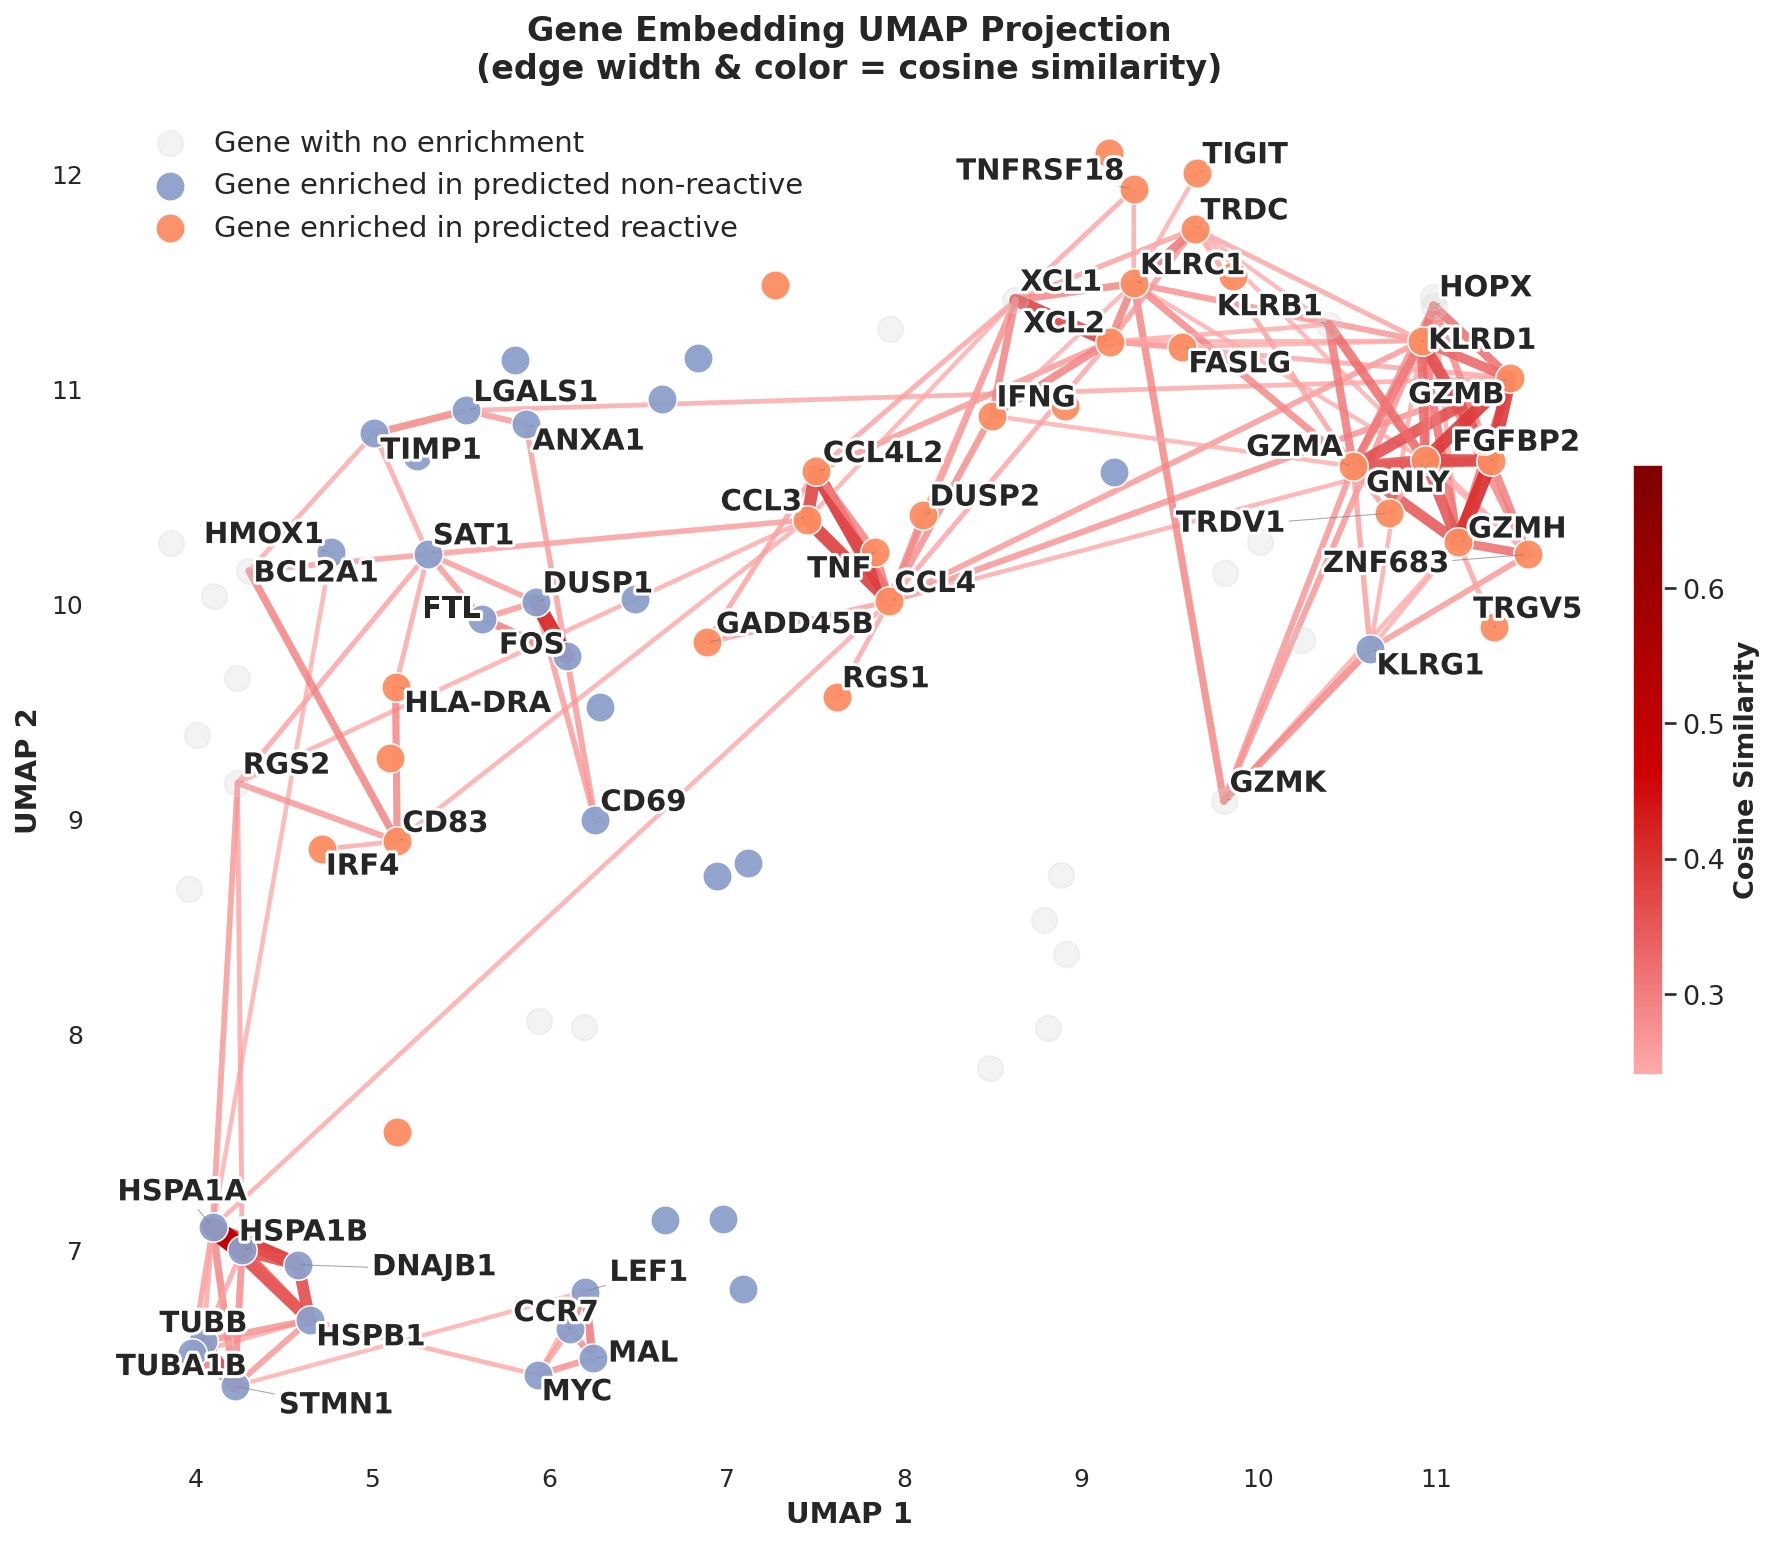

<frozen importlib._bootstrap>:914: ImportWarning: _SixMetaPathImporter.find_spec() not found; falling back to find_module()


In [57]:
# ════════════════════════════════════════════════════════════════════
# 3. Call
# ════════════════════════════════════════════════════════════════════
fig, ax, edges = plot_gene_umap_with_edges(
    gdata,
    gene_annotation_df_no_conflict,
    df_CD_sub,
    umap_key="X_umap",
    sim_thresh=0.24, # 0.249
    max_lw=15.0,
    min_lw=2.0,
    annotate_fontsize=14,
    top_n_annotate=30,
)

plt.show()

fig.savefig(output_dir / "GRN_gene_embedding_Chiffelle.pdf", dpi=300, transparent=True, bbox_inches="tight")
fig.savefig(output_dir / "GRN_gene_embedding_Chiffelle.svg", dpi=300, transparent=True, bbox_inches="tight")
fig.savefig(output_dir / "GRN_gene_embedding_Chiffelle.png", dpi=300, transparent=True, bbox_inches="tight")

In [58]:
import pandas as pd

# genes from cell type "1"
genes_type1 = pd.unique(
    pd.concat([
        edges.loc[edges["label_Gene"] == "1", "Gene"],
        edges.loc[edges["label_Gene1"] == "1", "Gene1"]
    ])
)

# genes from cell type "0"
genes_type0 = pd.unique(
    pd.concat([
        edges.loc[edges["label_Gene"] == "0", "Gene"],
        edges.loc[edges["label_Gene1"] == "0", "Gene1"]
    ])
)

# convert to Python lists if needed
genes_type1 = genes_type1.tolist()
genes_type0 = genes_type0.tolist()


In [59]:
genes_type1

['GZMB',
 'CCL4',
 'CCL3',
 'KLRD1',
 'GNLY',
 'CD83',
 'KLRC1',
 'ZNF683',
 'TRDC',
 'XCL2',
 'GZMA',
 'IFNG',
 'GZMH',
 'CCL4L2',
 'FASLG',
 'DUSP2',
 'GADD45B',
 'TNFRSF18',
 'FGFBP2',
 'HLA-DRA',
 'TIGIT',
 'RGS1',
 'TNF',
 'TRGV5',
 'IRF4',
 'TRDV1']

In [60]:
genes_type0

['LGALS1',
 'HSPA1A',
 'HMOX1',
 'HSPA1B',
 'STMN1',
 'LEF1',
 'SAT1',
 'KLRG1',
 'HSPB1',
 'MYC',
 'ANXA1',
 'FOS',
 'DUSP1',
 'CD69',
 'TIMP1',
 'TUBA1B',
 'TUBB',
 'DNAJB1',
 'FTL',
 'MAL',
 'CCR7']

In [61]:
pd.DataFrame({"genes_celltype_1": genes_type1}).to_csv(output_dir / "GRN_gene_embedding_Chiffelle_genes_celltype_1.csv", index=False)
pd.DataFrame({"genes_celltype_0": genes_type0}).to_csv(output_dir / "GRN_gene_embedding_Chiffelle_genes_celltype_0.csv", index=False)

In [62]:
list_unique_with_edges = list(pd.unique(edges[["Gene", "Gene1"]].values.ravel()))
print(len(list_unique_with_edges)) 
pd.DataFrame({"genes_withEdges": list_unique_with_edges}).to_csv(output_dir / "GRN_gene_embedding_genes_with_edges.csv", index=False)

53


In [63]:
output_dir

PosixPath('/cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/results/classifier/model_explainability/Model_expl_20260814/rankMin_study_clonotype')